# Q-learning nos ambientes Toy Text do Gymnasium

Atividade de **DIM0126 - Inteligência Artificial para Jogos I** (aula 3.5, aprendizado por reforço).

Exercício proposto nos slides:

1. Experimentar o Q-learning no Lago Congelado (`FrozenLake-v1`) usando o notebook do Colab disponibilizado;
2. Testar o Q-learning variando os hiperparâmetros (taxa de aprendizado, exploração, ...);
3. Testar o Q-learning em outros cenários do Toy Text.

O agente é o mesmo do notebook da disciplina (`FrozenLakeAgent`): Q-table, ε-greedy com decaimento linear de ε e
avaliação periódica da política gulosa. As mudanças em relação ao original:

- imports só do `gymnasium` (o original importava partes do pacote antigo `gym`, que não existe mais no Colab), sem vídeos;
- **mapa 8x8 aleatório gerado como no original (`generate_random_map(size=8, p=0.9)`), mas com semente fixa**,
  para que todas as configurações sejam comparadas no mesmo mapa (ver Experimento 1);
- cada configuração é treinada com **5 sementes**, e os resultados são reportados como média ± desvio padrão;
- a política gulosa é testada a cada 25 episódios (20 episódios de teste), e não a cada 100: com 100, quase todas as
  configurações já tinham convergido na primeira avaliação e a velocidade de aprendizado não aparecia;
- o agente sorteia a ação exploratória com o próprio gerador (`self.rng`), e não com `env.action_space.sample()`,
  para que cada semente seja reprodutível.

## 1. Setup

In [1]:
import importlib.util
if importlib.util.find_spec("gymnasium") is None:  # Colab sem gymnasium
    get_ipython().run_line_magic("pip", "install -q gymnasium")

import os
from collections import deque
from dataclasses import dataclass, replace

import gymnasium as gym
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

os.makedirs("figuras", exist_ok=True)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", None)
print("gymnasium", gym.__version__, "| numpy", np.__version__)

gymnasium 1.4.0 | numpy 2.5.4


### Hiperparâmetros

A configuração base é a do notebook original. Cada experimento muda **um** parâmetro por vez em relação a ela.

In [2]:
@dataclass(frozen=True)
class Config:
    alpha: float = 0.5            # taxa de aprendizado
    gamma: float = 0.95           # fator de desconto
    epsilon_inicial: float = 0.5  # exploração no início do treino
    epsilon_final: float = 0.1    # exploração mínima (decaimento linear até o último episódio)
    episodios: int = 5000
    freq_teste: int = 25          # avalia a política gulosa a cada N episódios (100 no original)
    episodios_teste: int = 20     # episódios em cada avaliação durante o treino (50 no original)
    episodios_teste_final: int = 500

BASE = Config()
SEEDS = [0, 1, 2, 3, 4]
BASE

Config(alpha=0.5, gamma=0.95, epsilon_inicial=0.5, epsilon_final=0.1, episodios=5000, freq_teste=25, episodios_teste=20, episodios_teste_final=500)

## 2. Agente Q-learning

Atualização (diferença temporal):

$$Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]$$

Se o episódio terminou (`terminated`), o alvo é só $r$. Se foi truncado pelo limite de passos (`truncated`), o estado
seguinte ainda tem valor e o alvo continua usando $\max_{a'} Q(s',a')$, como no original.

In [3]:
class QLearningAgent:
    def __init__(self, n_estados, n_acoes, cfg: Config, seed: int):
        self.cfg = cfg
        self.q_table = np.zeros((n_estados, n_acoes))
        self.epsilon = cfg.epsilon_inicial
        self.epsilon_decay = (cfg.epsilon_inicial - cfg.epsilon_final) / cfg.episodios
        self.rng = np.random.default_rng(seed)

    def eval_state(self, state):
        # ação gulosa; empates são desfeitos ao acaso
        q = self.q_table[state]
        return int(self.rng.choice(np.flatnonzero(q == q.max())))

    def choose_action(self, state):
        # ε-greedy: explora com probabilidade ε, senão age de forma gulosa
        if self.rng.uniform() < self.epsilon:
            return int(self.rng.integers(self.q_table.shape[1]))
        return self.eval_state(state)

    def update(self, state, action, reward, terminated, next_state):
        if terminated:
            target = reward
        else:
            target = reward + self.cfg.gamma * np.max(self.q_table[next_state])
        td_error = target - self.q_table[state, action]
        self.q_table[state, action] += self.cfg.alpha * td_error
        return td_error

    def decay_epsilon(self):
        self.epsilon = max(self.cfg.epsilon_final, self.epsilon - self.epsilon_decay)

## 3. Treino e avaliação

- **Treino**: a cada episódio o agente age com ε-greedy e atualiza a Q-table a cada passo. Guardamos a recompensa
  total do episódio (no FrozenLake é 1 se chegou ao objetivo e 0 caso contrário), o número de passos e o erro TD médio.
- **Teste**: a cada `freq_teste` episódios, a política gulosa (ε = 0) joga `episodios_teste` episódios sem aprender.
  No FrozenLake esse valor é a **taxa de sucesso**; nos outros ambientes, o retorno médio.
- **Avaliação final**: política gulosa em `episodios_teste_final` episódios ao fim do treino.
- **Repetições**: cada configuração roda com as 5 sementes de `SEEDS`, que controlam o agente e o ambiente.
- **Critério de parada**: número fixo de episódios (`episodios`); cada episódio termina ao atingir um estado terminal ou
  o limite de passos do ambiente (100 no FrozenLake, 200 no Taxi e no CliffWalking, que originalmente não tem limite;
  sem ele, uma política gulosa que anda em círculos nunca terminaria a avaliação).

In [4]:
def avaliar(env, agente, n_episodios):
    # retorno médio da política gulosa, sem exploração e sem atualizar a Q-table
    total = 0.0
    for _ in range(n_episodios):
        state, _ = env.reset()
        done = False
        while not done:
            state, reward, terminated, truncated, _ = env.step(agente.eval_state(state))
            total += reward
            done = terminated or truncated
    return total / n_episodios


def treinar(criar_env, cfg: Config, seed: int):
    env = criar_env()
    env.reset(seed=seed)
    agente = QLearningAgent(env.observation_space.n, env.action_space.n, cfg, seed)
    retornos, passos, erros, aval = [], [], [], []

    for episodio in range(cfg.episodios):
        state, _ = env.reset()
        done, total, n, erro = False, 0.0, 0, 0.0
        while not done:
            action = agente.choose_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            erro += abs(agente.update(state, action, reward, terminated, next_state))
            state = next_state
            total += reward
            n += 1
            done = terminated or truncated
        agente.decay_epsilon()
        retornos.append(total)
        passos.append(n)
        erros.append(erro / n)
        if (episodio + 1) % cfg.freq_teste == 0:
            aval.append(avaliar(env, agente, cfg.episodios_teste))

    final = avaliar(env, agente, cfg.episodios_teste_final)
    env.close()
    return {"retornos": np.array(retornos), "passos": np.array(passos), "erros": np.array(erros),
            "aval": np.array(aval), "final": final, "q_table": agente.q_table, "cfg": cfg}


def experimento(criar_env, cfg: Config = BASE, seeds=SEEDS):
    return [treinar(criar_env, cfg, s) for s in seeds]

### Métricas e gráficos

- `final`: desempenho da política gulosa no fim do treino (média ± desvio padrão entre as sementes);
- `treino (últ. 500)`: recompensa média dos últimos 500 episódios de treino (ainda com exploração ε);
- `ep. até X`: primeiro episódio em que o teste guloso atingiu o limiar (média entre as sementes que atingiram).

In [5]:
TABELA = []

def resumir(grupo, rotulo, runs, limiar=None, nome_limiar="ep. até 90% sucesso"):
    finais = np.array([r["final"] for r in runs])
    treino = np.array([r["retornos"][-500:].mean() for r in runs])
    linha = {"grupo": grupo, "configuração": rotulo,
             "final (média)": finais.mean(), "final (dp)": finais.std(),
             "treino últ. 500 (média)": treino.mean(), "treino últ. 500 (dp)": treino.std()}
    if limiar is not None:
        eps = []
        for r in runs:
            idx = np.flatnonzero(r["aval"] >= limiar)
            eps.append((idx[0] + 1) * r["cfg"].freq_teste if len(idx) else np.nan)
        eps = np.array(eps)
        atingiram = int((~np.isnan(eps)).sum())
        linha[nome_limiar] = f"{np.nanmean(eps):.0f} ({atingiram}/{len(runs)})" if atingiram else f"não atingiu (0/{len(runs)})"
    TABELA.append(linha)
    return linha


def tabela(grupo=None):
    df = pd.DataFrame(TABELA)
    if grupo is not None:
        df = df[df["grupo"] == grupo].dropna(axis=1, how="all")
    return df.round(3)


def media_movel(x, janela=100):
    return np.convolve(x, np.ones(janela) / janela, mode="valid")


def plot_curvas(grupos, titulo, arquivo, ylabel="taxa de sucesso", janela=100):
    # grupos: {rótulo: runs}. Linha = média entre sementes; faixa = ± 1 desvio padrão
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
    for rotulo, runs in grupos.items():
        mm = np.array([media_movel(r["retornos"], janela) for r in runs])
        x = np.arange(janela, janela + mm.shape[1])
        m, d = mm.mean(0), mm.std(0)
        axs[0].plot(x, m, label=rotulo)
        axs[0].fill_between(x, m - d, m + d, alpha=0.15)

        av = np.array([r["aval"] for r in runs])
        xa = np.arange(1, av.shape[1] + 1) * runs[0]["cfg"].freq_teste
        m, d = av.mean(0), av.std(0)
        axs[1].plot(xa, m, label=rotulo)
        axs[1].fill_between(xa, m - d, m + d, alpha=0.15)

        pm = np.array([media_movel(r["passos"], janela) for r in runs]).mean(0)
        axs[2].plot(x, pm, label=rotulo)

    axs[0].set(title="Treino (ε-greedy): recompensa média por episódio", xlabel="episódio",
               ylabel=f"recompensa (média móvel {janela})")
    axs[1].set(title="Teste (política gulosa)", xlabel="episódio", ylabel=ylabel)
    axs[2].set(title="Tamanho do episódio (treino)", xlabel="episódio", ylabel=f"passos (média móvel {janela})")
    axs[1].legend(fontsize=8)
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(f"figuras/{arquivo}.png", bbox_inches="tight")
    plt.show()


def plot_politica(q_table, desc, setas, titulo, arquivo, especiais="HG"):
    # mapa de calor de max_a Q(s,a) com a melhor ação de cada estado
    desc = np.array([list(linha) for linha in desc], dtype="U1")  # aceita lista de strings ou matriz
    linhas, colunas = desc.shape
    vmax = q_table.max(1).reshape(linhas, colunas)
    melhor = q_table.argmax(1).reshape(linhas, colunas)
    visitado = (q_table != 0).any(1).reshape(linhas, colunas)
    especial = np.isin(desc, list(especiais))
    anot = np.full(desc.shape, "", dtype=object)
    for i in range(linhas):
        for j in range(colunas):
            if visitado[i, j] and not especial[i, j]:
                anot[i, j] = setas[melhor[i, j]]
    vmax = np.where(especial, np.nan, vmax)  # células especiais (buraco, penhasco, objetivo) ficam em branco
    fig, ax = plt.subplots(figsize=(max(5, colunas * 0.7), max(4, linhas * 0.6)))
    sns.heatmap(vmax, annot=anot, fmt="", cmap="Blues", linewidths=0.7, linecolor="black",
                xticklabels=[], yticklabels=[], annot_kws={"fontsize": "x-large"}, ax=ax)
    for i, j in zip(*np.nonzero(especial)):
        ax.text(j + 0.5, i + 0.5, desc[i, j], ha="center", va="center", fontsize="x-large", color="dimgray")
    ax.set_title(titulo)
    fig.tight_layout()
    fig.savefig(f"figuras/{arquivo}.png", bbox_inches="tight")
    plt.show()


SETAS_FROZEN = {0: "←", 1: "↓", 2: "→", 3: "↑"}   # FrozenLake: 0 esq, 1 baixo, 2 dir, 3 cima
SETAS_CLIFF = {0: "↑", 1: "→", 2: "↓", 3: "←"}    # CliffWalking: 0 cima, 1 dir, 2 baixo, 3 esq

## 4. Ambientes

### FrozenLake-v1 (Lago Congelado)

- **Estados**: uma célula do grid, `linha * n_colunas + coluna` (16 no 4x4, 64 no 8x8).
- **Ações**: 4 (0 esquerda, 1 baixo, 2 direita, 3 cima).
- **Recompensa**: +1 ao chegar no objetivo `G`, 0 em todos os outros passos (inclusive ao cair num buraco `H`, que
  encerra o episódio). Limite de 100 passos.
- **`is_slippery=True`**: o agente só vai na direção escolhida com probabilidade 1/3; nas outras vezes, desliza para uma
  das direções perpendiculares.
- **Dificuldade**: recompensa esparsa. Até achar o objetivo por acaso a Q-table fica toda zerada e o agente anda ao acaso.

O mapa 8x8 é gerado como no notebook original (`generate_random_map(size=8, p=0.9)`), mas com `seed` fixa. A semente 9
foi escolhida por ser um mapa de dificuldade intermediária entre os 10 do Experimento 1 (com mais buracos e sem um
corredor livre óbvio); o mapa padrão 4x4 do Gymnasium também é usado:

In [6]:
MAPA_SEED = 9
MAPA_8X8 = generate_random_map(size=8, p=0.9, seed=MAPA_SEED)
MAPA_4X4 = gym.make("FrozenLake-v1", map_name="4x4").unwrapped.desc.astype(str)


def frozen_lake(desc=MAPA_8X8, escorregadio=False):
    return lambda: gym.make("FrozenLake-v1", desc=desc, is_slippery=escorregadio)


def menor_caminho(desc):
    # BFS do S até o G, evitando buracos (só para descrever a dificuldade do mapa)
    grid = [list(l) for l in desc]
    n = len(grid)
    inicio = next((i, j) for i in range(n) for j in range(n) if grid[i][j] == "S")
    fila, dist = deque([inicio]), {inicio: 0}
    while fila:
        i, j = fila.popleft()
        if grid[i][j] == "G":
            return dist[(i, j)]
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            a, b = i + di, j + dj
            if 0 <= a < n and 0 <= b < n and grid[a][b] != "H" and (a, b) not in dist:
                dist[(a, b)] = dist[(i, j)] + 1
                fila.append((a, b))


for nome, desc in [(f"8x8 (seed {MAPA_SEED})", MAPA_8X8), ("4x4 (padrão do Gymnasium)", MAPA_4X4)]:
    desc = ["".join(l) for l in desc]
    print(f"{nome}: {sum(l.count('H') for l in desc)} buracos, menor caminho = {menor_caminho(desc)} passos")
    print("\n".join(desc), end="\n\n")

env = frozen_lake()()
print("estados:", env.observation_space, "| ações:", env.action_space, "| limite de passos:", env.spec.max_episode_steps)
env.close()

8x8 (seed 9): 9 buracos, menor caminho = 14 passos
SFFFFHFH
FFFFFFHF
FFFFFFHH
FHFFHFFF
FFFFFHFF
FFFFHFFF
FFFFFFFF
FFFFFFFG

4x4 (padrão do Gymnasium): 4 buracos, menor caminho = 6 passos
SFFF
FHFH
FFFH
HFFG

estados: Discrete(64) | ações: Discrete(4) | limite de passos: 100


### CliffWalking-v1 (Caminhada no Penhasco)

- **Estados**: 48 (grid 4x12). O agente começa no canto inferior esquerdo e o objetivo fica no canto inferior direito.
- **Ações**: 4 (0 cima, 1 direita, 2 baixo, 3 esquerda).
- **Recompensa**: −1 por passo; −100 ao pisar no penhasco (as 10 células entre o início e o objetivo), o que manda o
  agente de volta ao início sem encerrar o episódio. O episódio acaba no objetivo. O retorno ótimo é −13. O ambiente
  não tem limite de passos; aqui usamos 200 (`max_episode_steps=200`).
- **Dificuldade**: o caminho mais curto passa colado no penhasco, então qualquer passo exploratório ali custa −100.

### Taxi-v4 (Táxi)

- **Estados**: 500 = 25 posições do táxi × 5 posições do passageiro (4 pontos + dentro do táxi) × 4 destinos.
- **Ações**: 6 (sul, norte, leste, oeste, pegar, deixar).
- **Recompensa**: −1 por passo, +20 ao deixar o passageiro no destino, −10 ao tentar pegar ou deixar em lugar errado.
  Limite de 200 passos.
- **Dificuldade**: espaço de estados bem maior e a tarefa tem duas etapas (buscar e entregar).

In [7]:
for nome in ["CliffWalking-v1", "Taxi-v4"]:
    env = gym.make(nome, max_episode_steps=200)
    print(f"{nome}: estados = {env.observation_space}, ações = {env.action_space}, limite = {env.spec.max_episode_steps}")
    env.close()

CliffWalking-v1: estados = Discrete(48), ações = Discrete(4), limite = 200
Taxi-v4: estados = Discrete(500), ações = Discrete(6), limite = 200


## 5. Experimento 0: configuração base (notebook original)

FrozenLake 8x8, `is_slippery=False`, α = 0.5, γ = 0.95, ε de 0.5 a 0.1, 5000 episódios, 5 sementes.

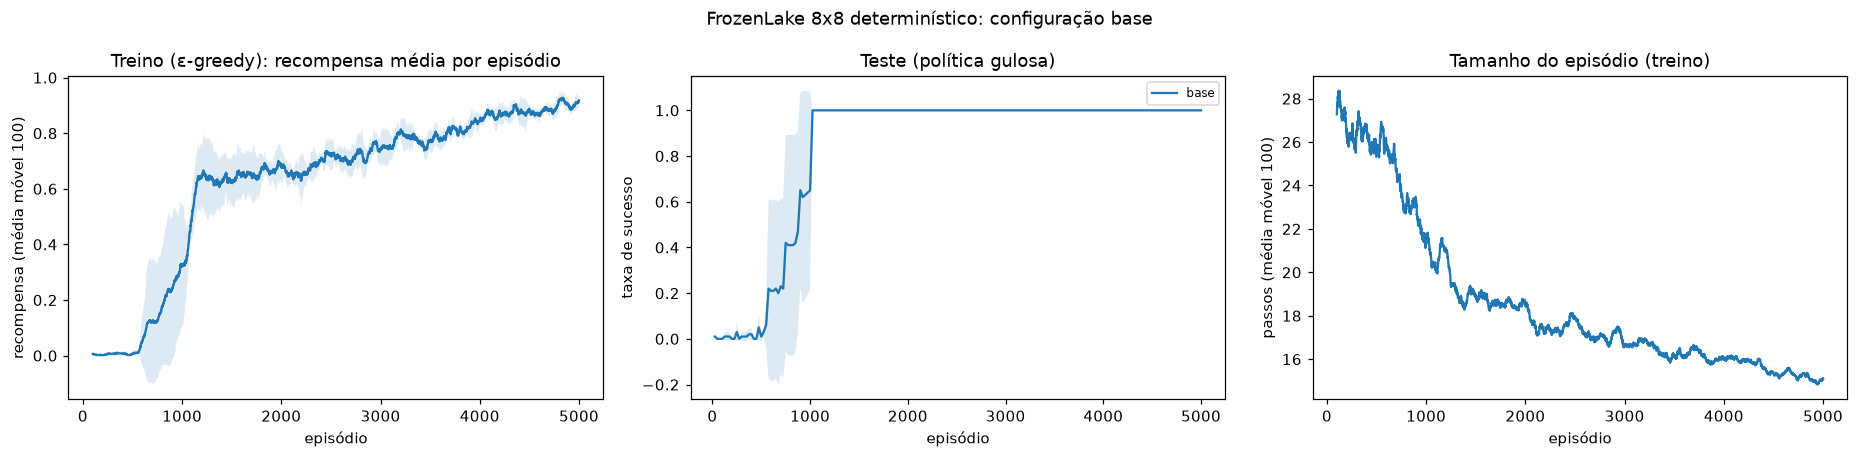

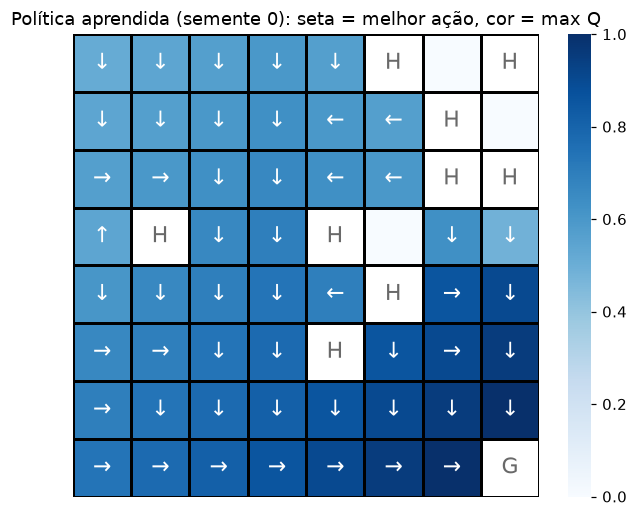

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 90% sucesso
0,0. base,"FrozenLake 8x8 determinístico, config. base",1.0,0.0,0.896,0.01,855 (5/5)


In [8]:
base = experimento(frozen_lake())
resumir("0. base", "FrozenLake 8x8 determinístico, config. base", base, limiar=0.9)
plot_curvas({"base": base}, "FrozenLake 8x8 determinístico: configuração base", "exp0_base")
plot_politica(base[0]["q_table"], MAPA_8X8, SETAS_FROZEN, "Política aprendida (semente 0): seta = melhor ação, cor = max Q",
              "exp0_politica")
tabela("0. base")

## 6. Experimento 1: mapa fixo × mapa aleatório

O notebook original gera um mapa novo a cada execução. Aqui a configuração base é treinada em **10 mapas diferentes**
(mesmo gerador, sementes 0 a 9; o mapa fixo dos outros experimentos é o de semente 9), com 3 sementes do agente em cada um, para medir quanto do resultado depende do mapa e
quanto depende do algoritmo.

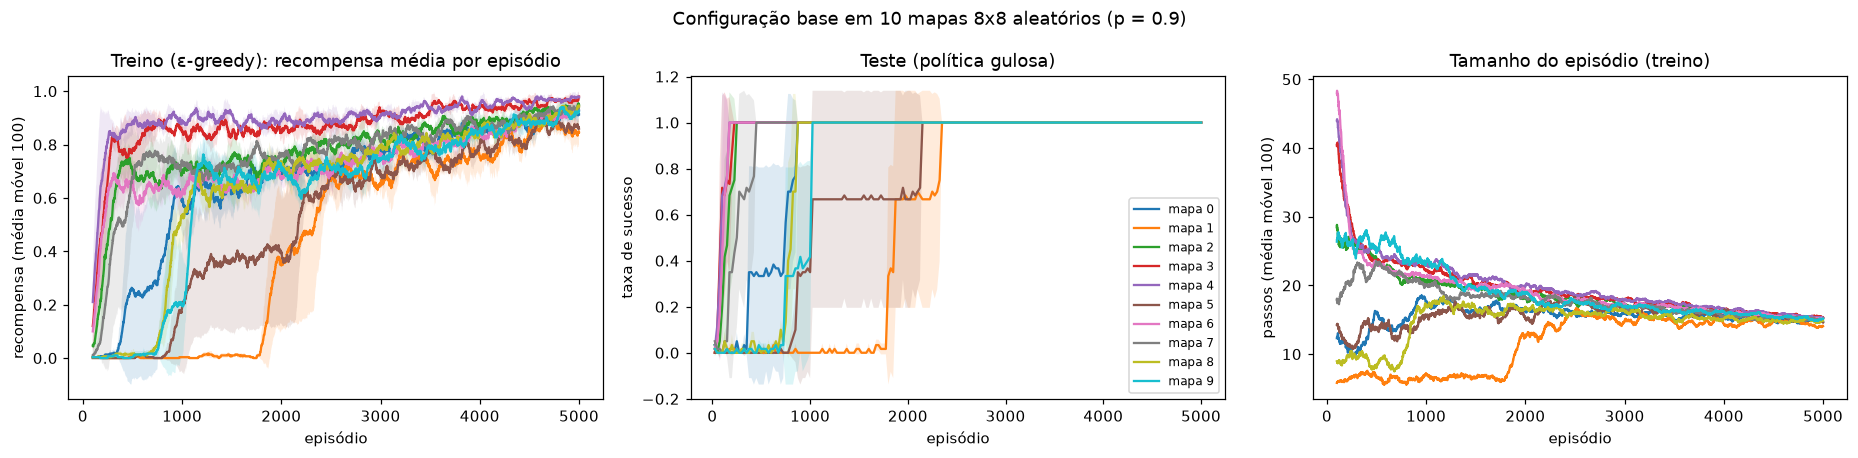

,mapa (seed),buracos,final (média),treino últ. 500,ep. até 90% sucesso
0,0,5,1.0,0.902,675.000
1,1,6,1.0,0.865,2008.333
2,2,3,1.0,0.931,183.333
3,3,3,1.0,0.963,133.333
4,4,3,1.0,0.971,125.000
5,5,5,1.0,0.871,1350.000
6,6,4,1.0,0.909,133.333
7,7,4,1.0,0.927,300.000
8,8,4,1.0,0.911,825.000
9,9,9,1.0,0.901,933.333


In [9]:
linhas_mapas, curvas_mapas = [], {}
for s in range(10):
    desc = generate_random_map(size=8, p=0.9, seed=s)
    runs = experimento(frozen_lake(desc), seeds=[0, 1, 2])
    curvas_mapas[f"mapa {s}"] = runs
    eps = [(np.flatnonzero(r["aval"] >= 0.9)[0] + 1) * BASE.freq_teste if (r["aval"] >= 0.9).any() else np.nan
           for r in runs]
    linhas_mapas.append({"mapa (seed)": s, "buracos": sum(l.count("H") for l in desc),
                         "final (média)": np.mean([r["final"] for r in runs]),
                         "treino últ. 500": np.mean([r["retornos"][-500:].mean() for r in runs]),
                         "ep. até 90% sucesso": np.nanmean(eps) if not np.isnan(eps).all() else np.nan})
mapas = pd.DataFrame(linhas_mapas).round(3)
plot_curvas(curvas_mapas, "Configuração base em 10 mapas 8x8 aleatórios (p = 0.9)", "exp1_mapas")
mapas

In [10]:
ep_base = [(np.flatnonzero(r["aval"] >= 0.9)[0] + 1) * BASE.freq_teste for r in base if (r["aval"] >= 0.9).any()]
print(f"Mapa fixo (seed {MAPA_SEED}), 5 sementes do agente: "
      f"ep. até 90% = {np.mean(ep_base):.0f} ± {np.std(ep_base):.0f}")
print(f"10 mapas aleatórios:                 "
      f"ep. até 90% = {mapas['ep. até 90% sucesso'].mean():.0f} ± {mapas['ep. até 90% sucesso'].std(ddof=0):.0f}")

Mapa fixo (seed 9), 5 sementes do agente: ep. até 90% = 855 ± 173
10 mapas aleatórios:                 ep. até 90% = 667 ± 599


## 7. Experimento 2: hiperparâmetros (FrozenLake 8x8 determinístico)

Cada bloco varia um parâmetro e mantém os outros na configuração base.

Observação: com transições determinísticas e recompensas sempre ≥ 0, qualquer α > 0 e γ > 0 tornam positivos os
valores Q do caminho até o objetivo, e a política gulosa só depende de quais Q são positivos. Por isso aqui os
hiperparâmetros devem mudar a **velocidade** do aprendizado e a recompensa durante o treino, mas não a política final.
O efeito sobre a política final é testado no 4x4 escorregadio (seção 7.5).

### 7.1 Taxa de aprendizado α

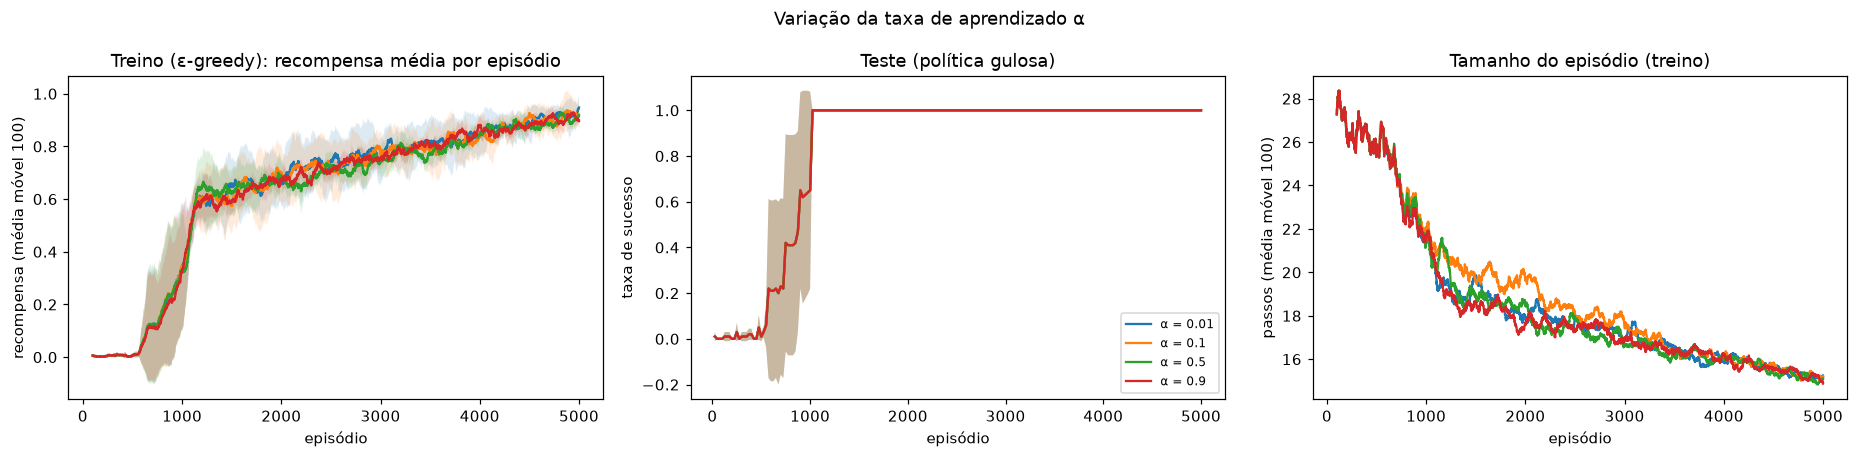

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 90% sucesso
1,2.1 α,α = 0.01,1.0,0.0,0.920,0.036,855 (5/5)
2,2.1 α,α = 0.1,1.0,0.0,0.906,0.057,855 (5/5)
3,2.1 α,α = 0.5,1.0,0.0,0.896,0.010,855 (5/5)
4,2.1 α,α = 0.9,1.0,0.0,0.901,0.007,855 (5/5)


In [11]:
runs_alpha = {}
for alpha in [0.01, 0.1, 0.5, 0.9]:
    runs_alpha[f"α = {alpha}"] = experimento(frozen_lake(), replace(BASE, alpha=alpha))
    resumir("2.1 α", f"α = {alpha}", runs_alpha[f"α = {alpha}"], limiar=0.9)
plot_curvas(runs_alpha, "Variação da taxa de aprendizado α", "exp2_alpha")
tabela("2.1 α")

### 7.2 Fator de desconto γ

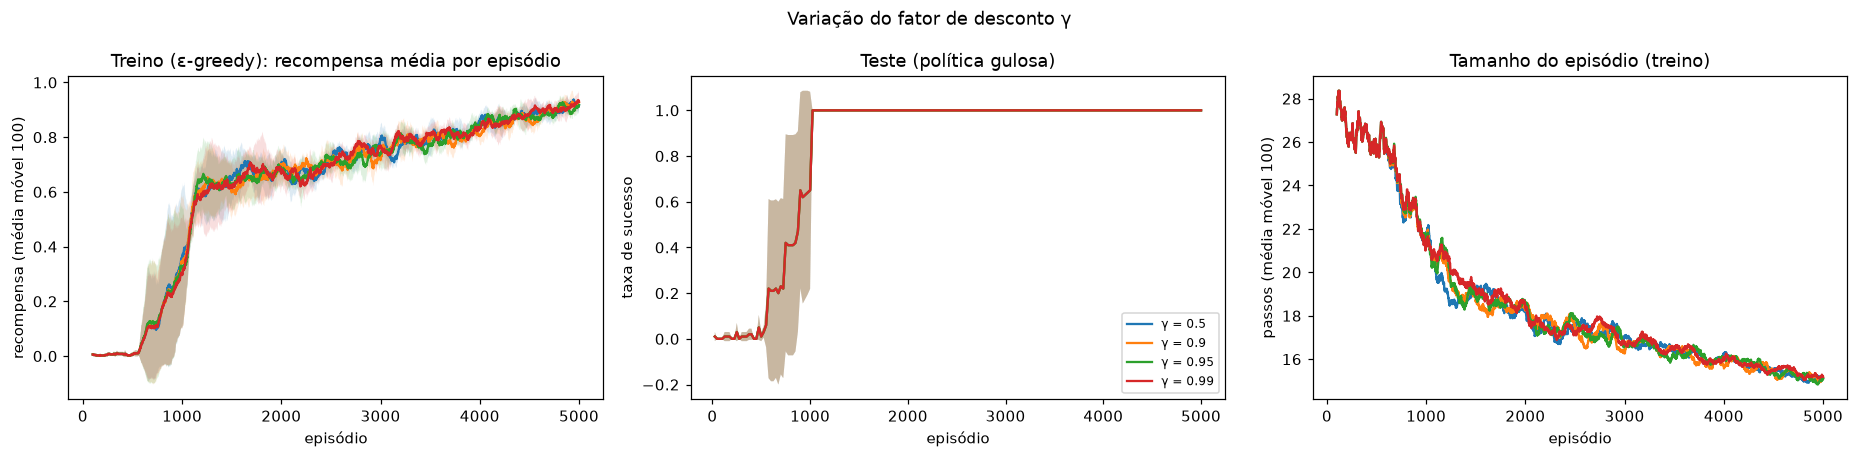

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 90% sucesso
5,2.2 γ,γ = 0.5,1.0,0.0,0.902,0.004,855 (5/5)
6,2.2 γ,γ = 0.9,1.0,0.0,0.905,0.014,855 (5/5)
7,2.2 γ,γ = 0.95,1.0,0.0,0.896,0.010,855 (5/5)
8,2.2 γ,γ = 0.99,1.0,0.0,0.908,0.021,855 (5/5)


In [12]:
runs_gamma = {}
for gamma in [0.5, 0.9, 0.95, 0.99]:
    runs_gamma[f"γ = {gamma}"] = experimento(frozen_lake(), replace(BASE, gamma=gamma))
    resumir("2.2 γ", f"γ = {gamma}", runs_gamma[f"γ = {gamma}"], limiar=0.9)
plot_curvas(runs_gamma, "Variação do fator de desconto γ", "exp2_gamma")
tabela("2.2 γ")

### 7.3 Exploração ε

Primeiro varia o ε inicial (com ε final = 0.1; ε inicial = 0.1 significa ε constante, sem decaimento). Depois varia o
ε final (com ε inicial = 0.5).

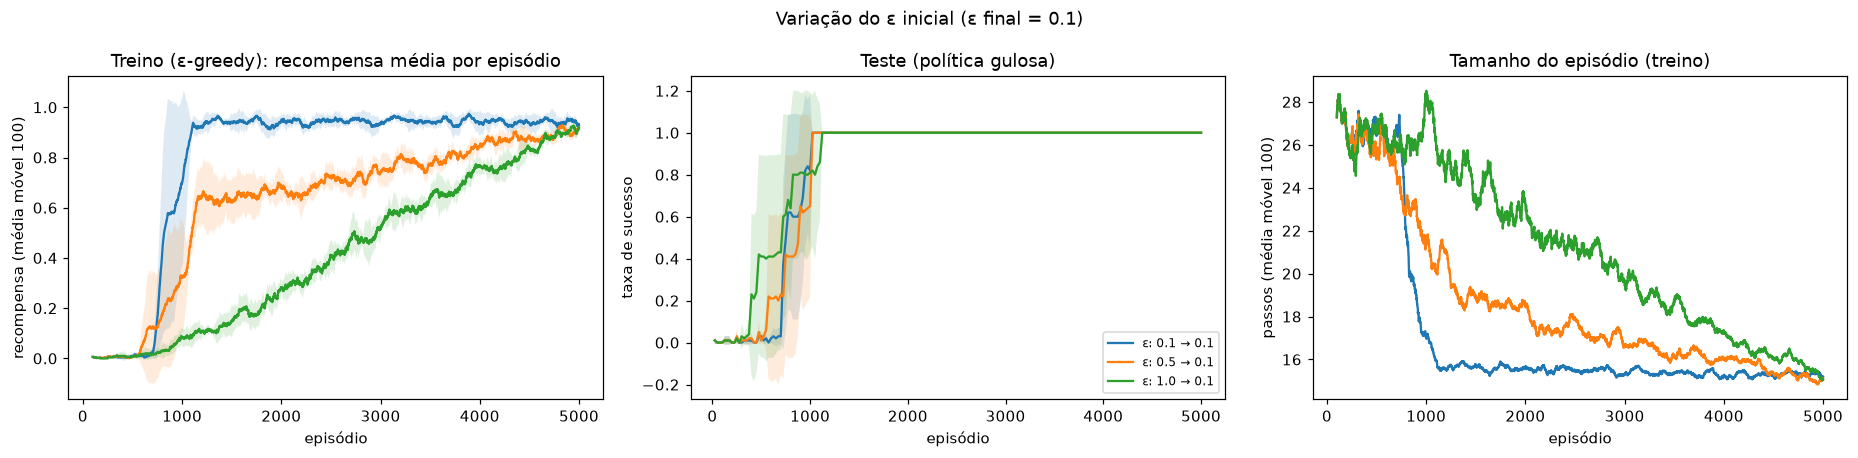

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 90% sucesso
9,2.3 ε inicial,ε inicial = 0.1,1.0,0.0,0.940,0.016,845 (5/5)
10,2.3 ε inicial,ε inicial = 0.5,1.0,0.0,0.896,0.010,855 (5/5)
11,2.3 ε inicial,ε inicial = 1.0,1.0,0.0,0.888,0.006,710 (5/5)


In [13]:
runs_eps = {}
for e0 in [0.1, 0.5, 1.0]:
    runs_eps[f"ε: {e0} → 0.1"] = experimento(frozen_lake(), replace(BASE, epsilon_inicial=e0))
    resumir("2.3 ε inicial", f"ε inicial = {e0}", runs_eps[f"ε: {e0} → 0.1"], limiar=0.9)
plot_curvas(runs_eps, "Variação do ε inicial (ε final = 0.1)", "exp2_epsilon_inicial")
tabela("2.3 ε inicial")

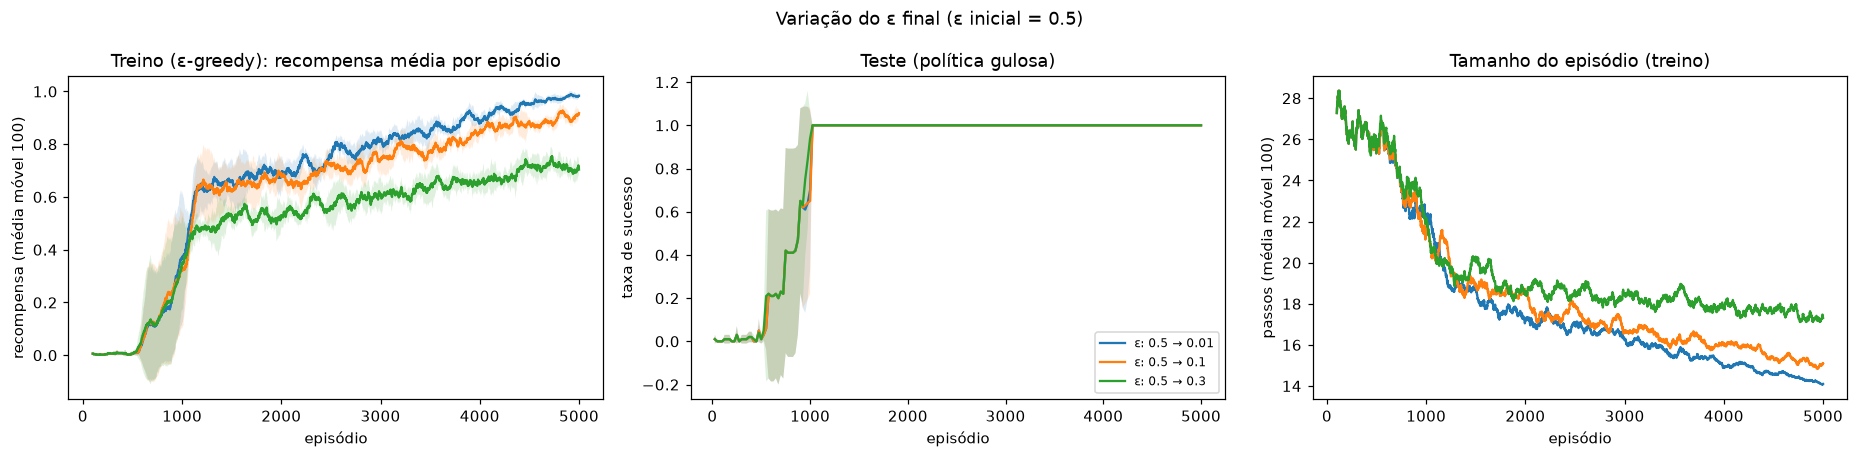

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 90% sucesso
12,2.4 ε final,ε final = 0.01,1.0,0.0,0.975,0.007,855 (5/5)
13,2.4 ε final,ε final = 0.1,1.0,0.0,0.896,0.010,855 (5/5)
14,2.4 ε final,ε final = 0.3,1.0,0.0,0.714,0.021,840 (5/5)


In [14]:
runs_epsf = {}
for e1 in [0.01, 0.1, 0.3]:
    runs_epsf[f"ε: 0.5 → {e1}"] = experimento(frozen_lake(), replace(BASE, epsilon_final=e1))
    resumir("2.4 ε final", f"ε final = {e1}", runs_epsf[f"ε: 0.5 → {e1}"], limiar=0.9)
plot_curvas(runs_epsf, "Variação do ε final (ε inicial = 0.5)", "exp2_epsilon_final")
tabela("2.4 ε final")

### 7.5 Hiperparâmetros no FrozenLake 4x4 escorregadio

No gelo escorregadio a mesma ação pode levar a estados diferentes, então a Q-table estima uma média de resultados
aleatórios. Aqui α (quanto cada experiência pesa), γ (quanto o agente valoriza chegar, contra o risco de cair no
caminho) e ε final passam a mudar a política aprendida. Mapa 4x4 padrão do Gymnasium, demais parâmetros na
configuração base.

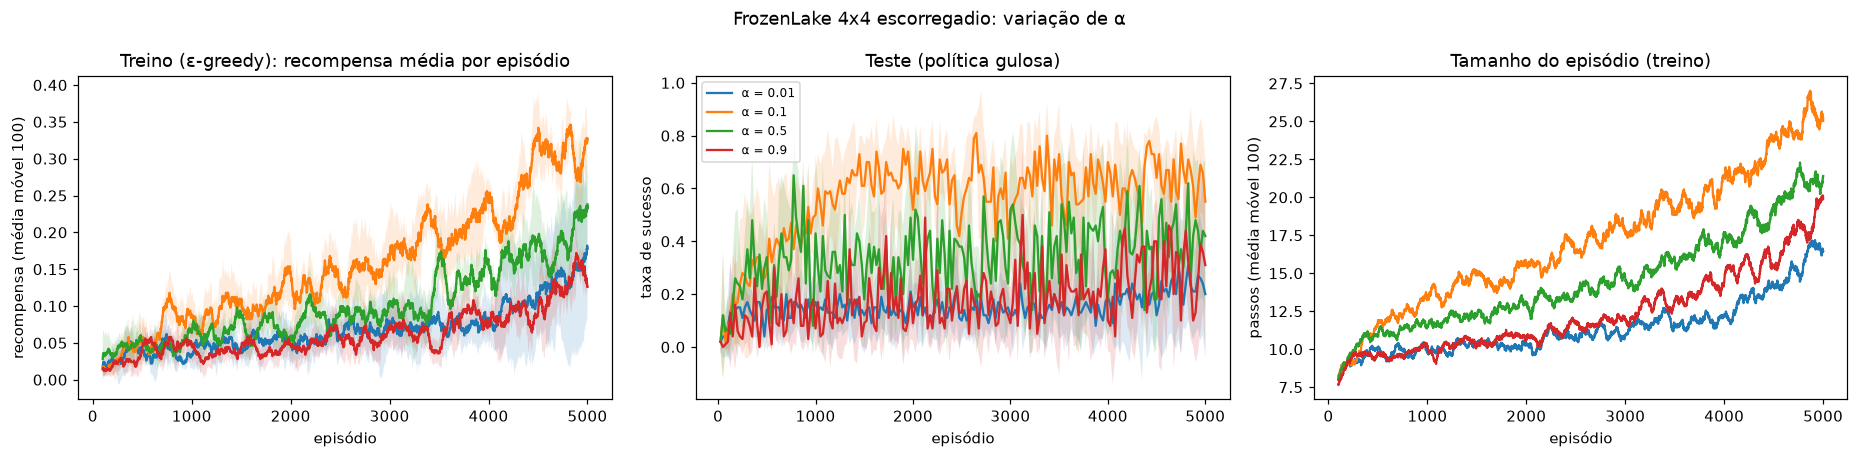

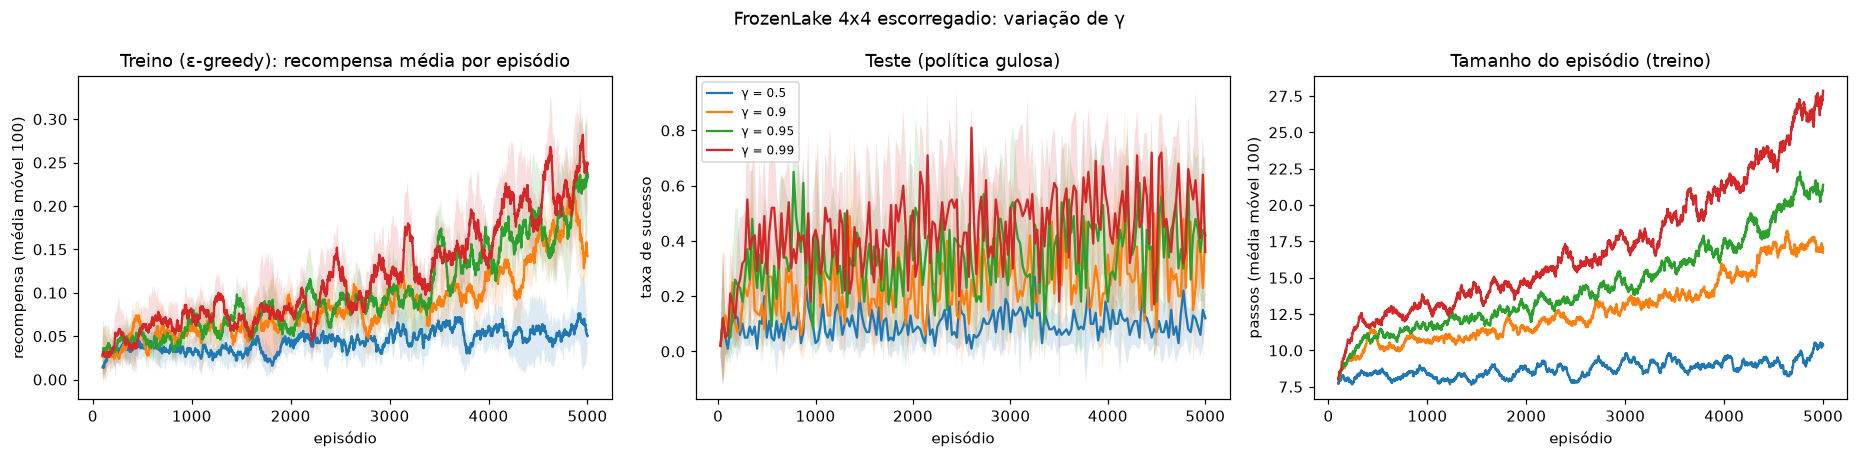

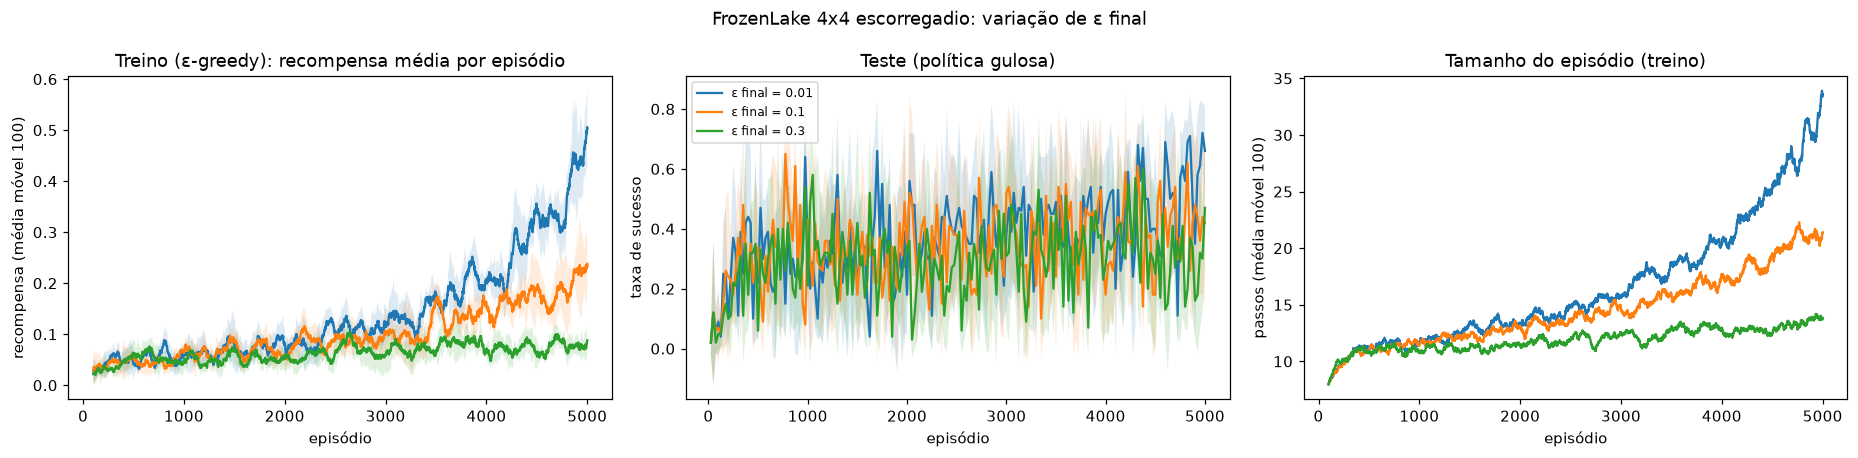

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 70% sucesso
15,2.5 4x4 escorregadio: α,α = 0.01,0.229,0.198,0.145,0.091,4075 (1/5)
16,2.5 4x4 escorregadio: α,α = 0.1,0.544,0.138,0.308,0.016,825 (5/5)
17,2.5 4x4 escorregadio: α,α = 0.5,0.400,0.241,0.194,0.022,535 (5/5)
18,2.5 4x4 escorregadio: α,α = 0.9,0.272,0.246,0.130,0.012,2085 (5/5)
19,2.5 4x4 escorregadio: γ,γ = 0.5,0.128,0.054,0.054,0.010,3800 (1/5)
20,2.5 4x4 escorregadio: γ,γ = 0.9,0.418,0.229,0.170,0.012,960 (5/5)
21,2.5 4x4 escorregadio: γ,γ = 0.95,0.400,0.241,0.194,0.022,535 (5/5)
22,2.5 4x4 escorregadio: γ,γ = 0.99,0.444,0.229,0.232,0.017,510 (5/5)
23,2.5 4x4 escorregadio: ε final,ε final = 0.01,0.665,0.106,0.389,0.036,425 (5/5)
24,2.5 4x4 escorregadio: ε final,ε final = 0.1,0.400,0.241,0.194,0.022,535 (5/5)


In [15]:
FL4_ESC = frozen_lake(MAPA_4X4, True)
runs_esc = {"α": {}, "γ": {}, "ε final": {}}
for alpha in [0.01, 0.1, 0.5, 0.9]:
    runs_esc["α"][f"α = {alpha}"] = experimento(FL4_ESC, replace(BASE, alpha=alpha))
for gamma in [0.5, 0.9, 0.95, 0.99]:
    runs_esc["γ"][f"γ = {gamma}"] = experimento(FL4_ESC, replace(BASE, gamma=gamma))
for e1 in [0.01, 0.1, 0.3]:
    runs_esc["ε final"][f"ε final = {e1}"] = experimento(FL4_ESC, replace(BASE, epsilon_final=e1))

for param, grupos in runs_esc.items():
    for rotulo, runs in grupos.items():
        resumir(f"2.5 4x4 escorregadio: {param}", rotulo, runs, limiar=0.7, nome_limiar="ep. até 70% sucesso")
    plot_curvas(grupos, f"FrozenLake 4x4 escorregadio: variação de {param}",
                f"exp2_escorregadio_{param.replace(' ', '_').replace('α', 'alpha').replace('γ', 'gamma').replace('ε', 'epsilon')}")
pd.concat([tabela(f"2.5 4x4 escorregadio: {p}") for p in runs_esc])

## 8. Experimento 3: variações do FrozenLake

Tamanho do mapa (4x4 padrão × 8x8 aleatório) e gelo escorregadio. O 8x8 escorregadio também é treinado com 20000
episódios, com α = 0.5 e com α = 0.1, para ver se o problema é falta de treino ou o tamanho do passo de aprendizado.

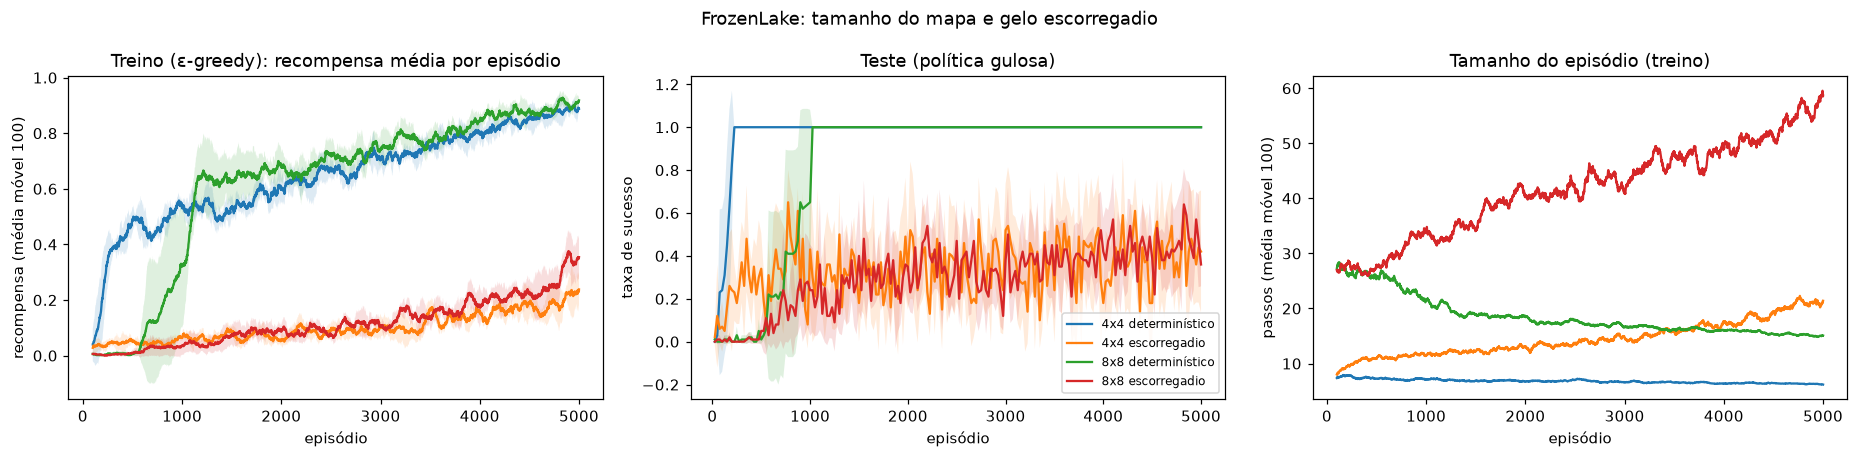

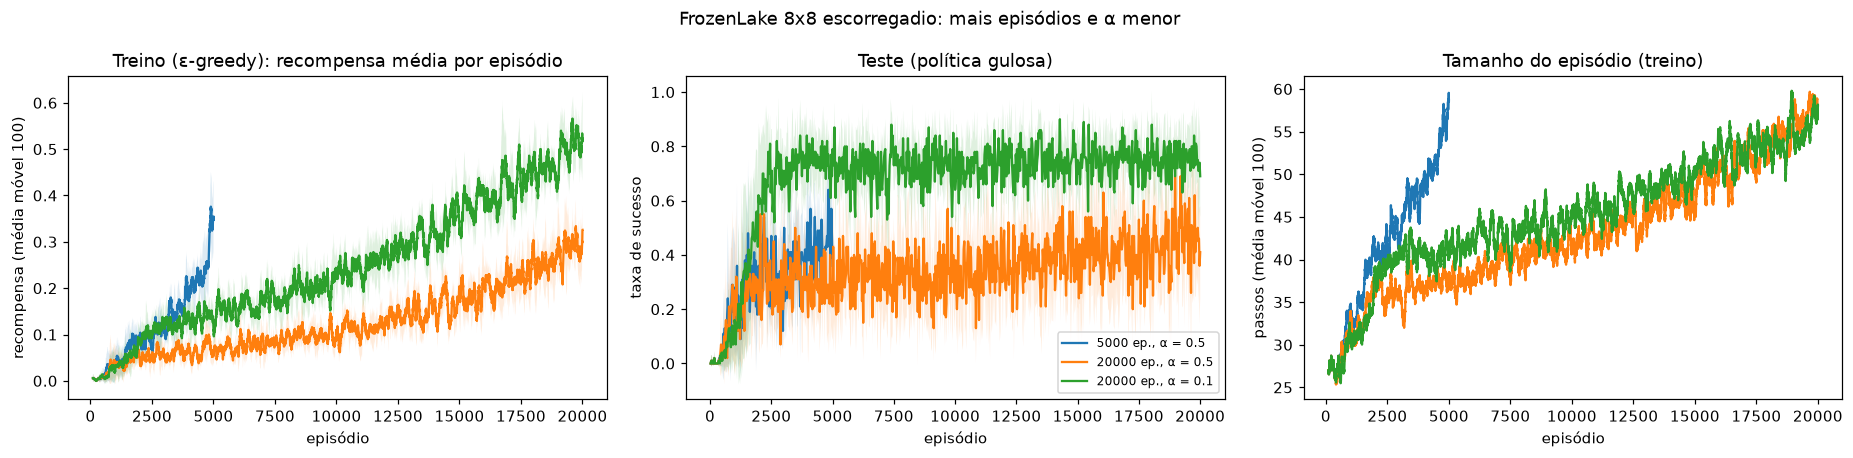

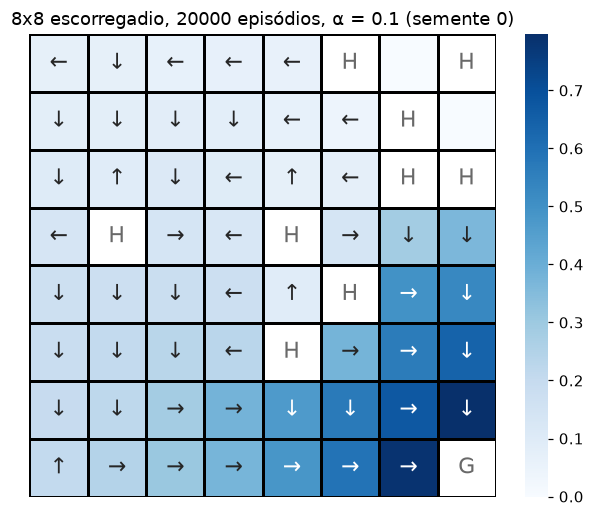

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 70% sucesso
26,3. FrozenLake,4x4 determinístico,1.000,0.000,0.873,0.019,165 (5/5)
27,3. FrozenLake,4x4 escorregadio,0.400,0.241,0.194,0.022,535 (5/5)
28,3. FrozenLake,8x8 determinístico,1.000,0.000,0.896,0.010,855 (5/5)
29,3. FrozenLake,8x8 escorregadio,0.390,0.115,0.289,0.050,1475 (5/5)
30,3. FrozenLake,"8x8 escorregadio, 20000 episódios",0.412,0.145,0.294,0.015,1840 (5/5)
31,3. FrozenLake,"8x8 escorregadio, 20000 episódios, α = 0.1",0.694,0.196,0.523,0.013,1890 (5/5)


In [16]:
runs_fl = {
    "4x4 determinístico": experimento(frozen_lake(MAPA_4X4, False)),
    "4x4 escorregadio": experimento(frozen_lake(MAPA_4X4, True)),
    "8x8 determinístico": base,
    "8x8 escorregadio": experimento(frozen_lake(MAPA_8X8, True)),
}
for rotulo, runs in runs_fl.items():
    resumir("3. FrozenLake", rotulo, runs, limiar=0.7, nome_limiar="ep. até 70% sucesso")
runs_fl_20k = experimento(frozen_lake(MAPA_8X8, True), replace(BASE, episodios=20000))
resumir("3. FrozenLake", "8x8 escorregadio, 20000 episódios", runs_fl_20k, limiar=0.7, nome_limiar="ep. até 70% sucesso")
runs_fl_20k_a01 = experimento(frozen_lake(MAPA_8X8, True), replace(BASE, episodios=20000, alpha=0.1))
resumir("3. FrozenLake", "8x8 escorregadio, 20000 episódios, α = 0.1", runs_fl_20k_a01, limiar=0.7,
        nome_limiar="ep. até 70% sucesso")

plot_curvas(runs_fl, "FrozenLake: tamanho do mapa e gelo escorregadio", "exp3_frozenlake")
plot_curvas({"5000 ep., α = 0.5": runs_fl["8x8 escorregadio"], "20000 ep., α = 0.5": runs_fl_20k,
             "20000 ep., α = 0.1": runs_fl_20k_a01},
            "FrozenLake 8x8 escorregadio: mais episódios e α menor", "exp3_escorregadio_20k")
plot_politica(runs_fl_20k_a01[0]["q_table"], MAPA_8X8, SETAS_FROZEN,
              "8x8 escorregadio, 20000 episódios, α = 0.1 (semente 0)", "exp3_politica_escorregadio")
tabela("3. FrozenLake")

## 9. Experimento 4: outros ambientes do Toy Text

Mesma configuração base (α = 0.5, γ = 0.95, ε de 0.5 a 0.1, 5000 episódios). Aqui a métrica é o **retorno** do episódio
(soma das recompensas), não a taxa de sucesso. O limiar de "retorno ótimo" é −13 no CliffWalking e 8 no Taxi
(o `reward_threshold` registrado no Gymnasium; o ótimo médio é 8.46).

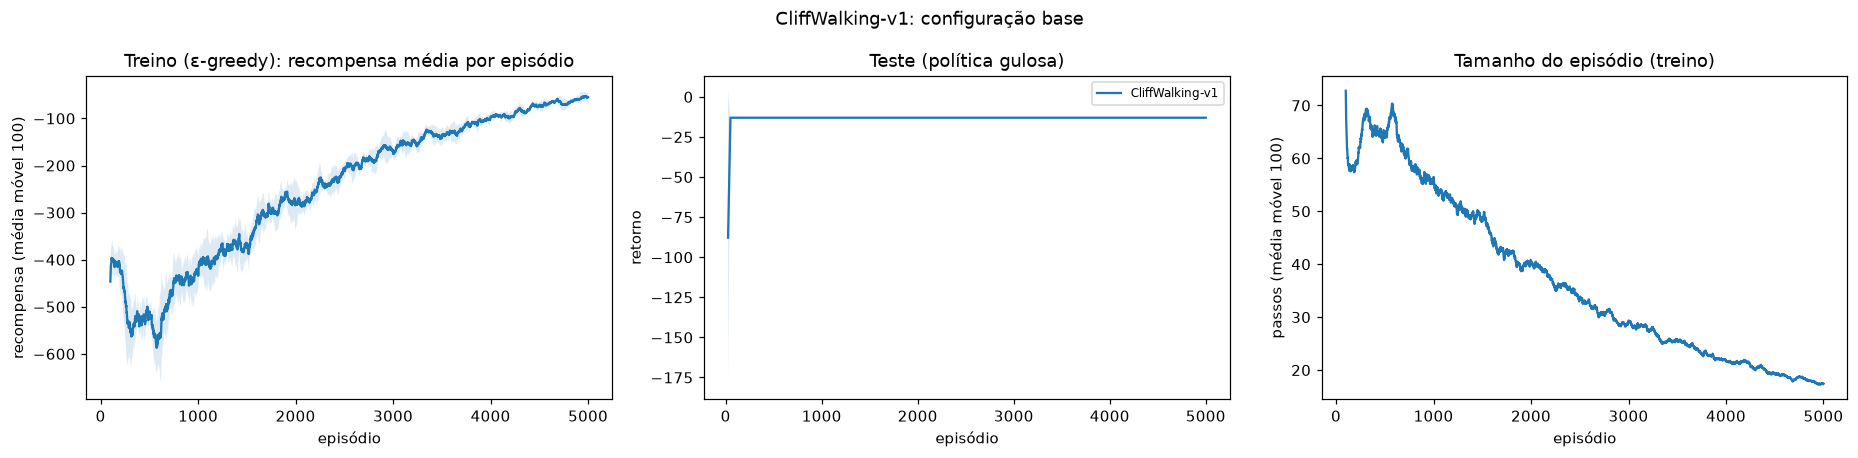

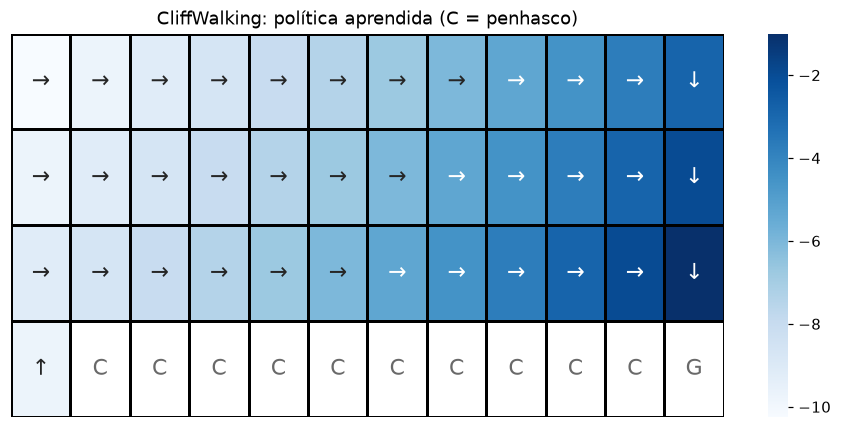

In [17]:
runs_cliff = experimento(lambda: gym.make("CliffWalking-v1", max_episode_steps=200))
resumir("4. outros ambientes", "CliffWalking-v1", runs_cliff, limiar=-13, nome_limiar="ep. até retorno ótimo")
plot_curvas({"CliffWalking-v1": runs_cliff}, "CliffWalking-v1: configuração base", "exp4_cliffwalking", ylabel="retorno")

desc_cliff = np.full((4, 12), "", dtype="U1")
desc_cliff[3, 1:11] = "C"
desc_cliff[3, 11] = "G"
plot_politica(runs_cliff[0]["q_table"], desc_cliff, SETAS_CLIFF,
              "CliffWalking: política aprendida (C = penhasco)", "exp4_cliff_politica", especiais="CG")

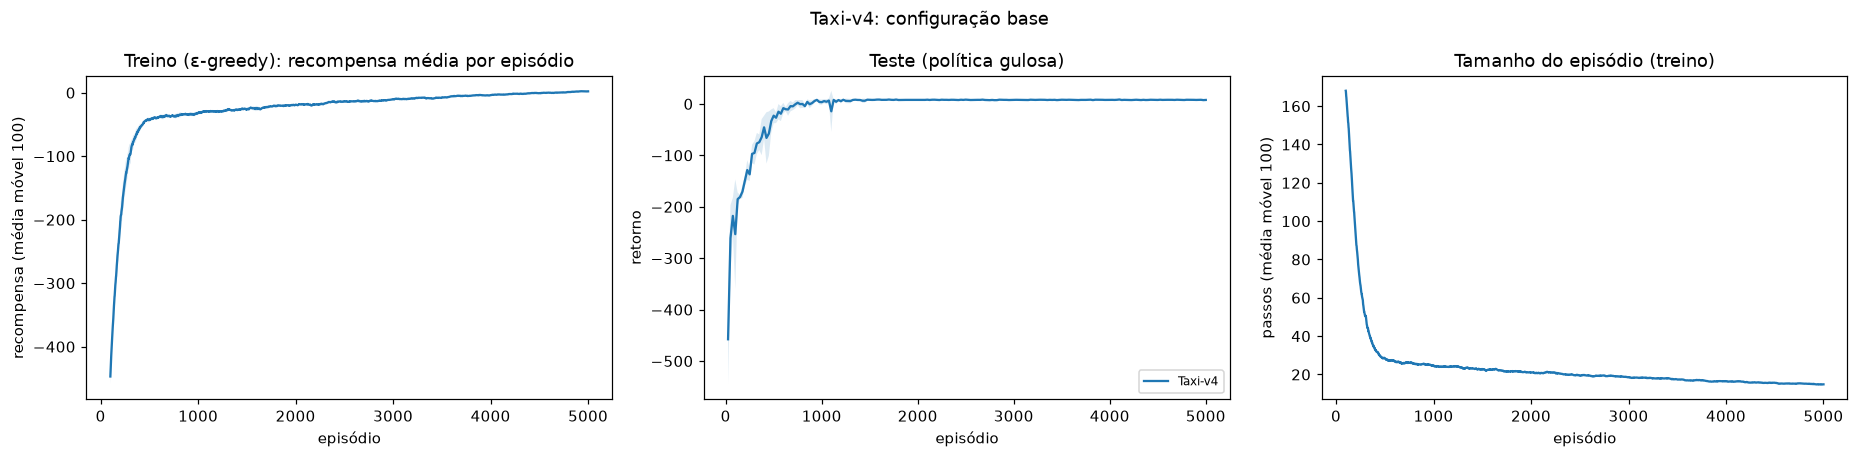

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até retorno ótimo
32,4. outros ambientes,CliffWalking-v1,-13.000,0.000,-62.766,3.238,35 (5/5)
33,4. outros ambientes,Taxi-v4,7.897,0.074,1.068,0.165,715 (5/5)


In [18]:
runs_taxi = experimento(lambda: gym.make("Taxi-v4"))
resumir("4. outros ambientes", "Taxi-v4", runs_taxi, limiar=8, nome_limiar="ep. até retorno ótimo")
plot_curvas({"Taxi-v4": runs_taxi}, "Taxi-v4: configuração base", "exp4_taxi", ylabel="retorno")
tabela("4. outros ambientes")

## 10. Tabela geral

In [19]:
geral = tabela()
geral.to_csv("resultados.csv", index=False)
geral

,grupo,configuração,final (média),final (dp),treino últ. 500 (média),treino últ. 500 (dp),ep. até 90% sucesso,ep. até 70% sucesso,ep. até retorno ótimo
0,0. base,"FrozenLake 8x8 determinístico, config. base",1.000,0.000,0.896,0.010,855 (5/5),NaN,NaN
1,2.1 α,α = 0.01,1.000,0.000,0.920,0.036,855 (5/5),NaN,NaN
2,2.1 α,α = 0.1,1.000,0.000,0.906,0.057,855 (5/5),NaN,NaN
3,2.1 α,α = 0.5,1.000,0.000,0.896,0.010,855 (5/5),NaN,NaN
4,2.1 α,α = 0.9,1.000,0.000,0.901,0.007,855 (5/5),NaN,NaN
5,2.2 γ,γ = 0.5,1.000,0.000,0.902,0.004,855 (5/5),NaN,NaN
6,2.2 γ,γ = 0.9,1.000,0.000,0.905,0.014,855 (5/5),NaN,NaN
7,2.2 γ,γ = 0.95,1.000,0.000,0.896,0.010,855 (5/5),NaN,NaN
8,2.2 γ,γ = 0.99,1.000,0.000,0.908,0.021,855 (5/5),NaN,NaN
9,2.3 ε inicial,ε inicial = 0.1,1.000,0.000,0.940,0.016,845 (5/5),NaN,NaN
